**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

In [1]:
import sys
import subprocess
import importlib.util

for module, package in [("kagglehub", "kagglehub"), ("prophet", "prophet"), ("tensorflow", "tensorflow")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)


**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

In [2]:
dataset_dir = Path(kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india"))
csv_files = sorted(dataset_dir.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"CSV-файли не знайдено у {dataset_dir}. Завантажте CSV з Kaggle вручну.")
print("Доступні CSV:")
for path in csv_files:
    print(" -", path.name)
preferred = [p for p in csv_files if "2013_to_2024" in p.name.lower()]
csv_path = preferred[0] if preferred else max(csv_files, key=lambda p: p.stat().st_size)
print("Обрано:", csv_path)


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Доступні CSV:
 - kaggel_weather_2013_to_2024.csv
Обрано: /kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv



1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [3]:
raw_df = pd.read_csv(csv_path)
display(raw_df.head())
print("Розмір датасету:", raw_df.shape)
print("Стовпці:", list(raw_df.columns))


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Розмір датасету: (3557, 29)
Стовпці: ['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp', 'feelslikemax', 'feelslikemin', 'feelslike', 'humidity', 'precip', 'precipprob', 'precipcover', 'windspeed', 'sealevelpressure', 'conditions', 'Year', 'month', 'dayofweek', 'dayofyear', 'year-2000', 'weekofyear', 'tempmax_humidity', 'tempmin_humidity', 'temp_humidity', 'feelslikemax_humidity', 'feelslikemin_humidity', 'feelslike_humidity', 'temp_range', 'heat_index']


Підготовка даних

In [4]:
df = raw_df.copy()
df.columns = df.columns.str.strip()
date_candidates = [c for c in df.columns if c.lower() in ("date", "datetime", "timestamp", "day")]
if not date_candidates:
    date_candidates = [c for c in df.columns if "date" in c.lower()]
if not date_candidates:
    raise ValueError("Не знайдено стовпець із датою: " + str(list(df.columns)))
date_col = date_candidates[0]
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df = df.dropna(subset=[date_col]).sort_values(date_col).drop_duplicates(subset=[date_col])
df = df.set_index(date_col)
df.index.name = "DATE"

names = ["meantemp", "mean_temp", "temperature", "temp", "tavg", "avgtemp", "temperature_2m_mean", "temp_mean"]
temperature_col = next((c for name in names for c in df.columns if c.lower() == name), None)
if temperature_col is None:
    temperature_col = next((c for c in df.columns if "temp" in c.lower() and "max" not in c.lower() and "min" not in c.lower()), None)
if temperature_col is None:
    raise ValueError("Не знайдено стовпець температури: " + str(list(df.columns)))
df[temperature_col] = pd.to_numeric(df[temperature_col], errors="coerce")
df = df[[temperature_col]].rename(columns={temperature_col: "temperature"})
df = df.resample("D").mean()
df["temperature"] = df["temperature"].interpolate(method="time", limit_direction="both")
if df["temperature"].isna().any():
    raise ValueError("Після обробки залишилися пропущені значення температури")
print("Період:", df.index.min().date(), "-", df.index.max().date())
display(df.head())


Період: 2013-04-14 - 2024-11-30


,temperature
DATE,
2013-04-14,28.7
2013-04-15,28.6
2013-04-16,31.7
2013-04-17,29.9
2013-04-18,30.6


In [5]:
df.info()
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   temperature  4249 non-null   float64
dtypes: float64(1)
memory usage: 66.4 KB


,temperature
count,4249.000000
mean,25.431466
std,7.228744
min,6.500000
25%,19.100000
50%,27.853846
75%,31.007692
max,39.500000


In [6]:
print("Пропуски в початкових даних:")
print(raw_df.isna().sum())
print("Пропуски після підготовки:")
print(df.isna().sum())
print("Дублікати дат після обробки:", df.index.duplicated().sum())


Пропуски в початкових даних:
Unnamed: 0               0
DATE                     0
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64
Пропуски після підготовки:
temperature    0
dtype: int64
Дублікати дат після обробки: 0


Графік температури

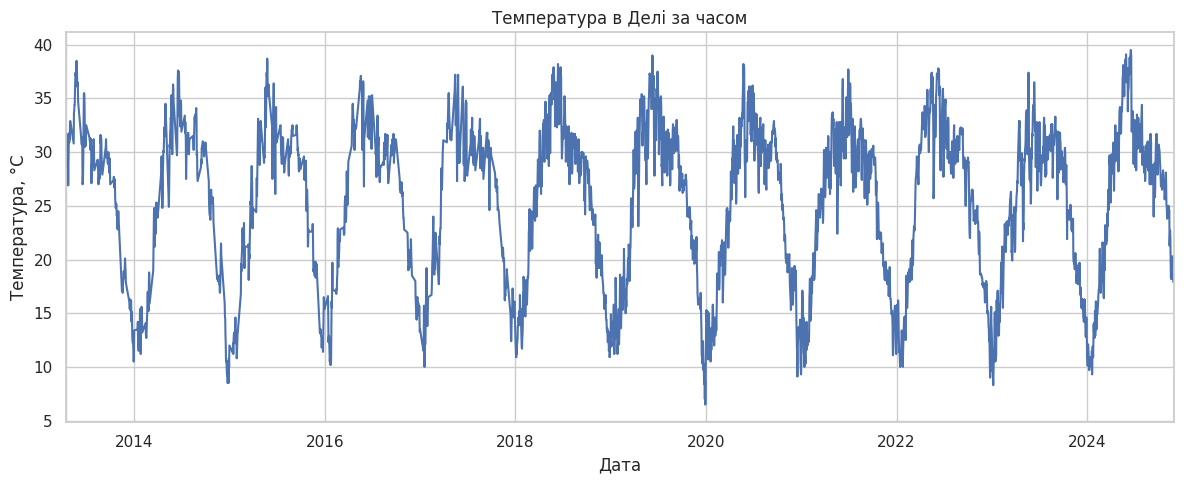

In [7]:
df["temperature"].plot(title="Температура в Делі за часом", ylabel="Температура, °C")
plt.xlabel("Дата")
plt.tight_layout()
plt.show()


Ковзне середнє

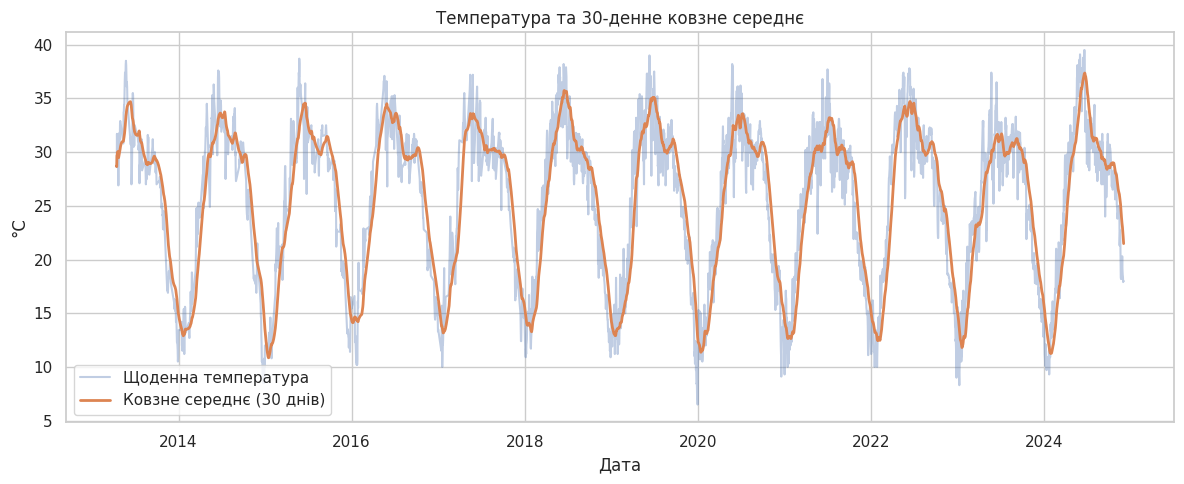

In [8]:
rolling_30 = df["temperature"].rolling(window=30, min_periods=1).mean()
plt.plot(df.index, df["temperature"], alpha=0.35, label="Щоденна температура")
plt.plot(df.index, rolling_30, label="Ковзне середнє (30 днів)", linewidth=2)
plt.title("Температура та 30-денне ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("°C")
plt.legend()
plt.tight_layout()
plt.show()


Розподіл температури

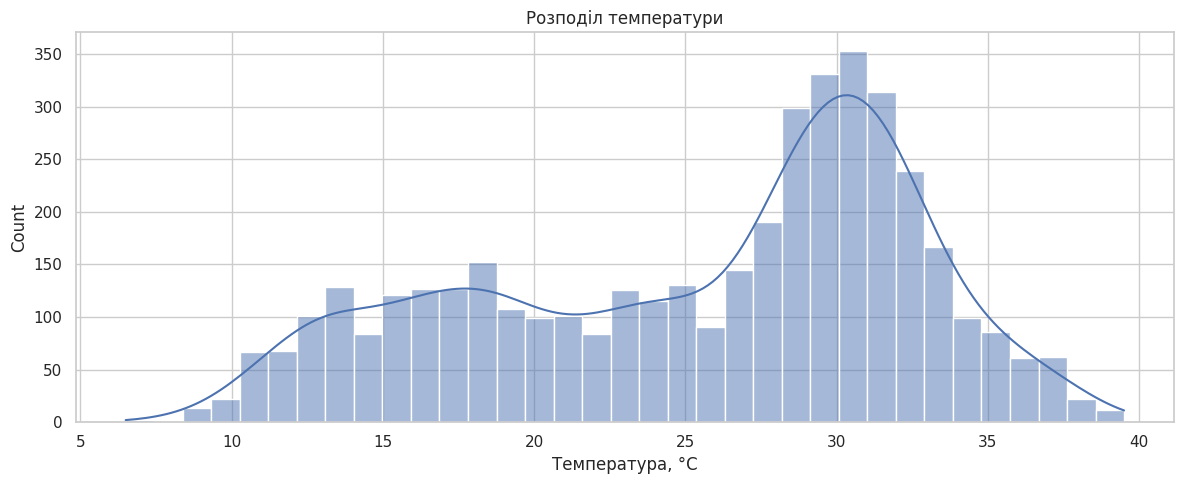

In [9]:
sns.histplot(data=df, x="temperature", bins=35, kde=True)
plt.title("Розподіл температури")
plt.xlabel("Температура, °C")
plt.tight_layout()
plt.show()


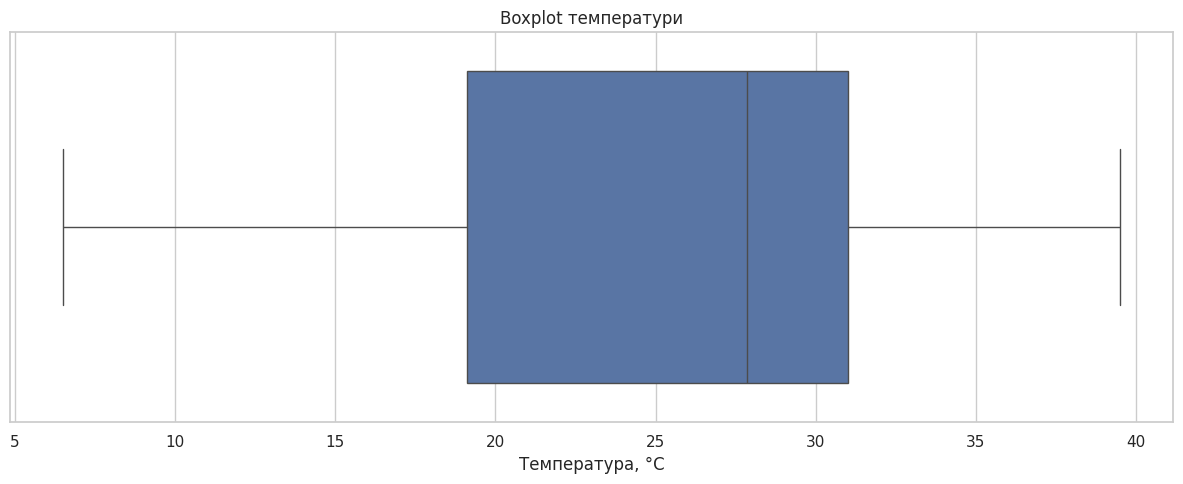

Потенційні викиди за правилом IQR: 0


In [10]:
sns.boxplot(x=df["temperature"])
plt.title("Boxplot температури")
plt.xlabel("Температура, °C")
plt.tight_layout()
plt.show()
q1, q3 = df.temperature.quantile([0.25, 0.75])
iqr = q3 - q1
outlier_count = ((df.temperature < q1 - 1.5 * iqr) | (df.temperature > q3 + 1.5 * iqr)).sum()
print(f"Потенційні викиди за правилом IQR: {outlier_count}")


Аналіз автокореляції
ACF

PACF

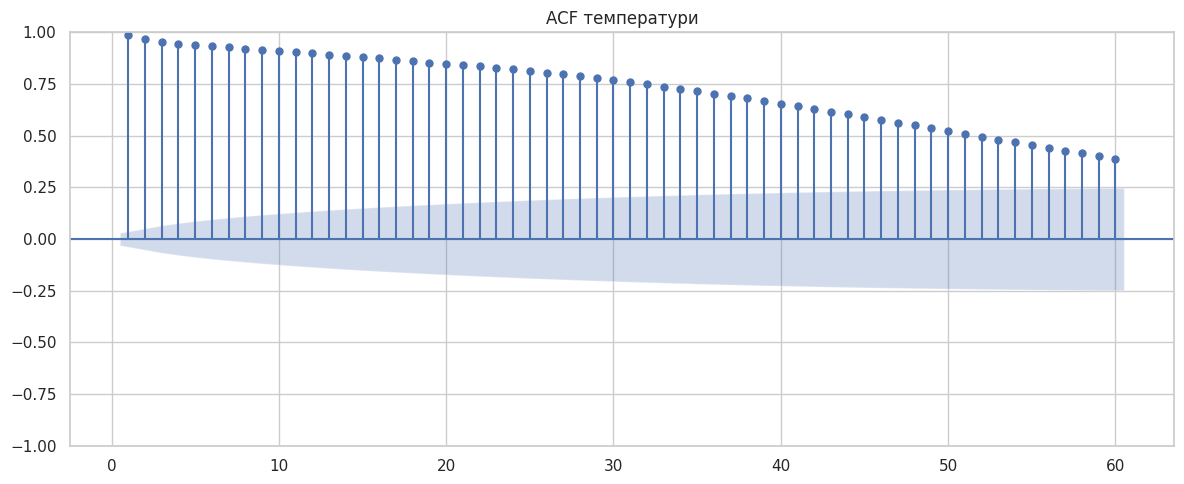

In [11]:
plot_acf(df["temperature"], lags=min(60, len(df) // 3), zero=False)
plt.title("ACF температури")
plt.tight_layout()
plt.show()


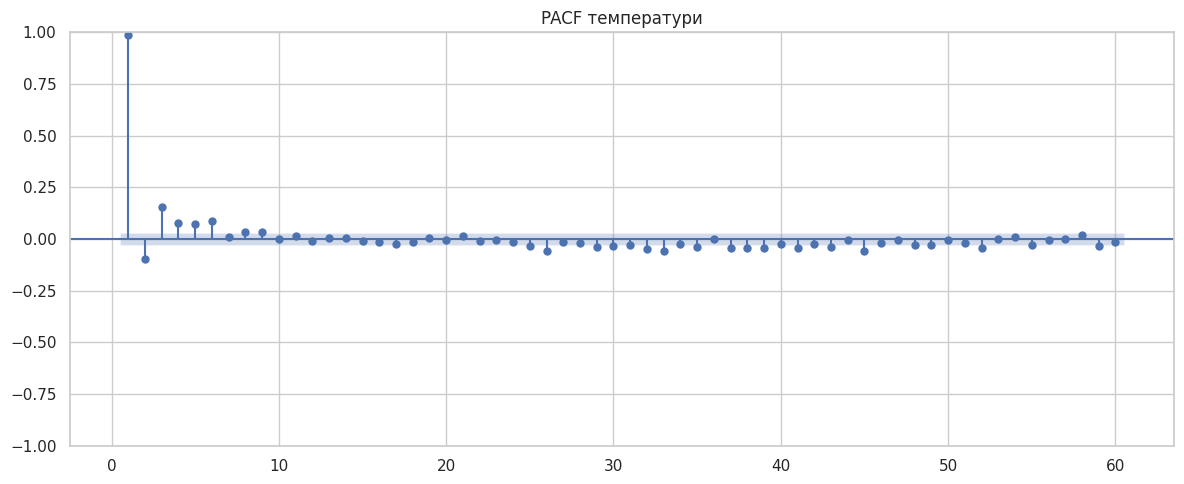

ACF показує кореляцію ряду з попередніми значеннями, PACF — зв'язок з конкретним лагом без впливу проміжних лагів.


In [12]:
plot_pacf(df["temperature"], lags=min(60, len(df) // 3 - 1), method="ywm", zero=False)
plt.title("PACF температури")
plt.tight_layout()
plt.show()
print("ACF показує кореляцію ряду з попередніми значеннями, PACF — зв'язок з конкретним лагом без впливу проміжних лагів.")


In [13]:
series = df["temperature"].astype("float32")
split_idx = int(len(series) * 0.8)
train = series.iloc[:split_idx]
test = series.iloc[split_idx:]
print("Train:", len(train), train.index.min().date(), "-", train.index.max().date())
print("Test:", len(test), test.index.min().date(), "-", test.index.max().date())

def mape(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    mask = np.abs(actual) > 1e-8
    return float(np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100) if mask.any() else float("nan")

def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": mape(y_true, y_pred),
    }


Train: 3399 2013-04-14 - 2022-08-03
Test: 850 2022-08-04 - 2024-11-30


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Сезонну динаміку річного циклу враховуємо додатковими Fourier-ознаками.
def fourier_features(index, period=365.25, order=3, origin=None):
    origin = index.min() if origin is None else origin
    days = np.asarray((index - origin).days, dtype=float)
    data = {}
    for k in range(1, order + 1):
        data[f"sin_{k}"] = np.sin(2 * np.pi * k * days / period)
        data[f"cos_{k}"] = np.cos(2 * np.pi * k * days / period)
    return pd.DataFrame(data, index=index)

origin_date = train.index.min()
train_exog = fourier_features(train.index, origin=origin_date)
test_exog = fourier_features(test.index, origin=origin_date)
arima_model = ARIMA(train, order=(2, 0, 2), exog=train_exog, enforce_stationarity=False, enforce_invertibility=False)
arima_result = arima_model.fit()
arima_pred = pd.Series(np.asarray(arima_result.forecast(steps=len(test), exog=test_exog)), index=test.index, name="ARIMA")
display(arima_pred.head())


,ARIMA
DATE,
2022-08-04,30.558294
2022-08-05,30.440876
2022-08-06,30.351806
2022-08-07,30.283328
2022-08-08,30.229914


In [15]:
print(arima_result.summary())


                               SARIMAX Results                                
Dep. Variable:            temperature   No. Observations:                 3399
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -5261.737
Date:                Thu, 29 Oct 2026   AIC                          10547.475
Time:                        06:32:25   BIC                          10621.039
Sample:                    04-14-2013   HQIC                         10573.769
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         25.2281      0.184    137.259      0.000      24.868      25.588
sin_1          9.2248      0.209     44.051      0.000       8.814       9.635
cos_1          1.7152      0.237      7.236      0.0

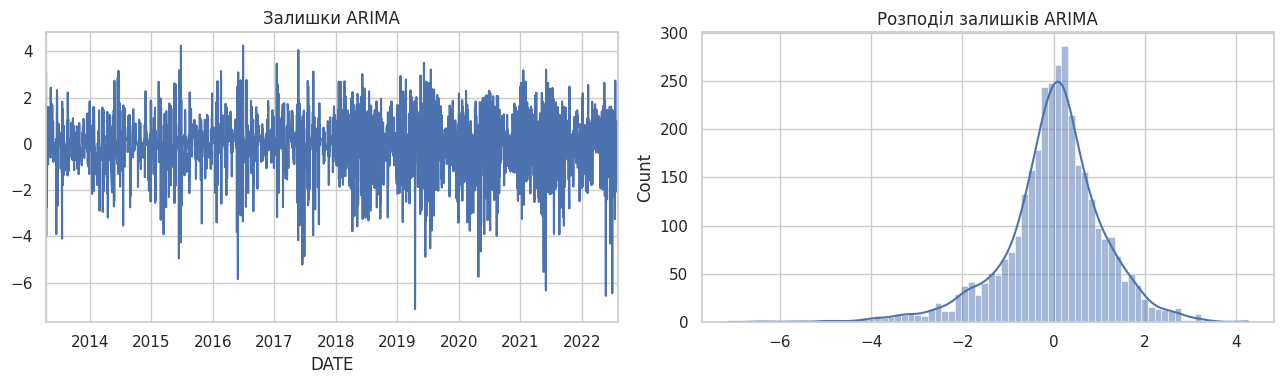

In [16]:
residuals = arima_result.resid.dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
residuals.plot(ax=axes[0], title="Залишки ARIMA")
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Розподіл залишків ARIMA")
plt.tight_layout()
plt.show()


In [17]:
arima_scores = metrics(test, arima_pred)
print("ARIMA:", {k: round(v, 3) for k, v in arima_scores.items()})


ARIMA: {'MAE': 1.742, 'RMSE': np.float64(2.267), 'MAPE (%)': 7.601}


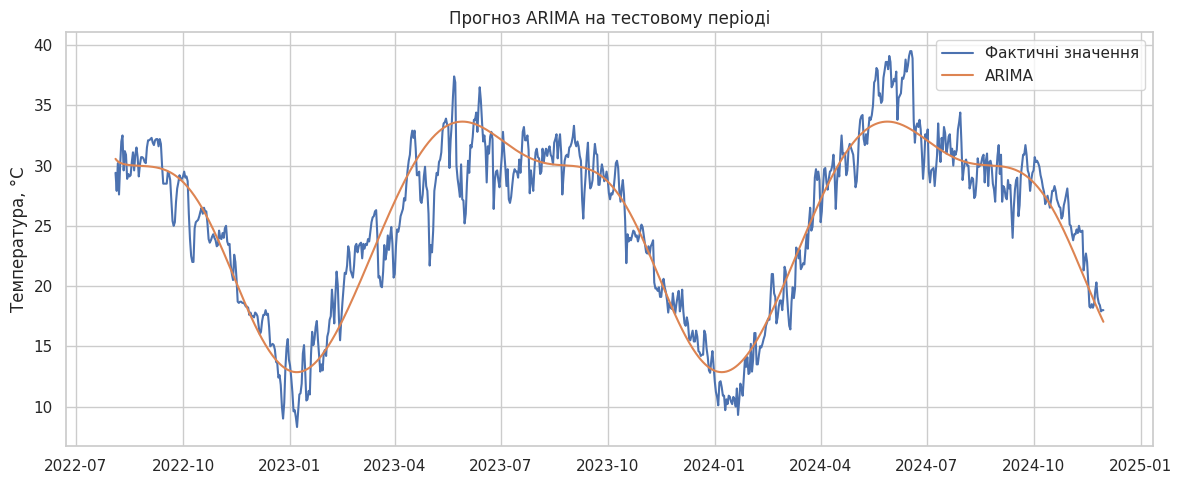

In [18]:
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(arima_pred.index, arima_pred, label="ARIMA")
plt.title("Прогноз ARIMA на тестовому періоді")
plt.ylabel("Температура, °C")
plt.legend()
plt.tight_layout()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
prophet_train = train.rename("y").reset_index().rename(columns={"DATE": "ds"})
prophet_train["ds"] = pd.to_datetime(prophet_train["ds"])
display(prophet_train.head())


,ds,y
0,2013-04-14,28.700001
1,2013-04-15,28.600000
2,2013-04-16,31.700001
3,2013-04-17,29.900000
4,2013-04-18,30.600000


In [20]:
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, changepoint_prior_scale=0.05)
prophet_model.fit(prophet_train)


Прогноз

In [21]:
prophet_future = pd.DataFrame({"ds": test.index})
prophet_forecast = prophet_model.predict(prophet_future)
prophet_pred = pd.Series(prophet_forecast["yhat"].to_numpy(), index=test.index, name="Prophet")
display(prophet_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.428858,27.841067,32.956220
1,2022-08-05,30.500378,28.181350,33.148159
2,2022-08-06,30.576375,28.011200,33.101657
3,2022-08-07,30.654511,28.123791,33.091183
4,2022-08-08,30.732471,28.136692,33.305102


In [22]:
prophet_scores = metrics(test, prophet_pred)
print("Prophet:", {k: round(v, 3) for k, v in prophet_scores.items()})


Prophet: {'MAE': 2.069, 'RMSE': np.float64(2.648), 'MAPE (%)': 9.349}


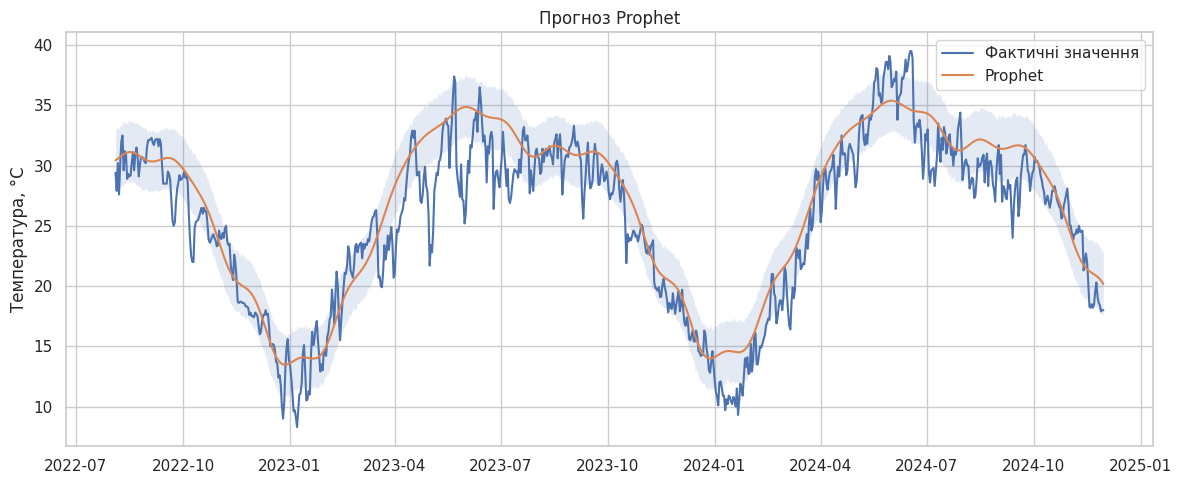

In [23]:
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(prophet_pred.index, prophet_pred, label="Prophet")
plt.fill_between(test.index, prophet_forecast["yhat_lower"], prophet_forecast["yhat_upper"], alpha=0.15)
plt.title("Прогноз Prophet")
plt.ylabel("Температура, °C")
plt.legend()
plt.tight_layout()
plt.show()


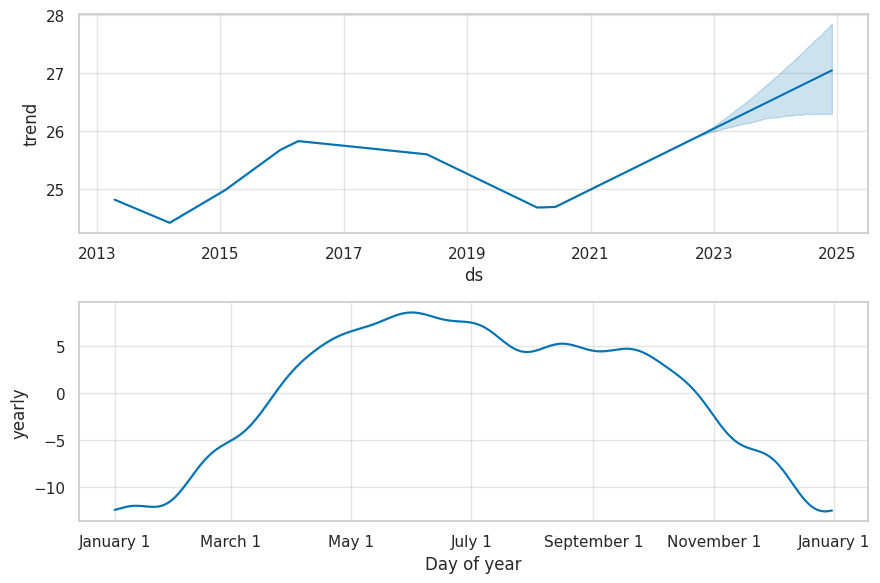

In [24]:
prophet_model.plot_components(prophet_model.predict(prophet_model.make_future_dataframe(periods=len(test), freq="D")))
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
window = 30
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train.to_numpy().reshape(-1, 1))
scaled_full = scaler.transform(series.to_numpy().reshape(-1, 1))

def make_sequences(values, lookback):
    X, y, indices = [], [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i, 0])
        y.append(values[i, 0])
        indices.append(i)
    return np.array(X, dtype=np.float32)[..., np.newaxis], np.array(y, dtype=np.float32), np.array(indices)

X_all, y_all, target_indices = make_sequences(scaled_full, window)
print("Форма послідовностей:", X_all.shape)


Форма послідовностей: (4219, 30, 1)


In [26]:
train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
assert len(X_test) == len(test)
print("Train LSTM:", X_train.shape, "Test LSTM:", X_test.shape)


Train LSTM: (3369, 30, 1) Test LSTM: (850, 30, 1)


In [27]:
lstm_model = Sequential([
    Input(shape=(window, 1)),
    LSTM(48),
    Dense(24, activation="relu"),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mse")


Epoch 1/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0393 - val_loss: 0.0050
Epoch 2/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0040 - val_loss: 0.0044
Epoch 3/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0035 - val_loss: 0.0040
Epoch 4/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0032 - val_loss: 0.0038
Epoch 5/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0029 - val_loss: 0.0037
Epoch 6/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0028 - val_loss: 0.0036
Epoch 7/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0027 - val_loss: 0.0036
Epoch 8/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0026 - val_loss: 0.0035
Epoch 9/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0025 - val_loss: 0.0035
Epoch 10/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0024 - val_loss: 0.0034
Epoch 11/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0023 - val_loss: 0.0033
Epoch 12/35
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0023 - val_

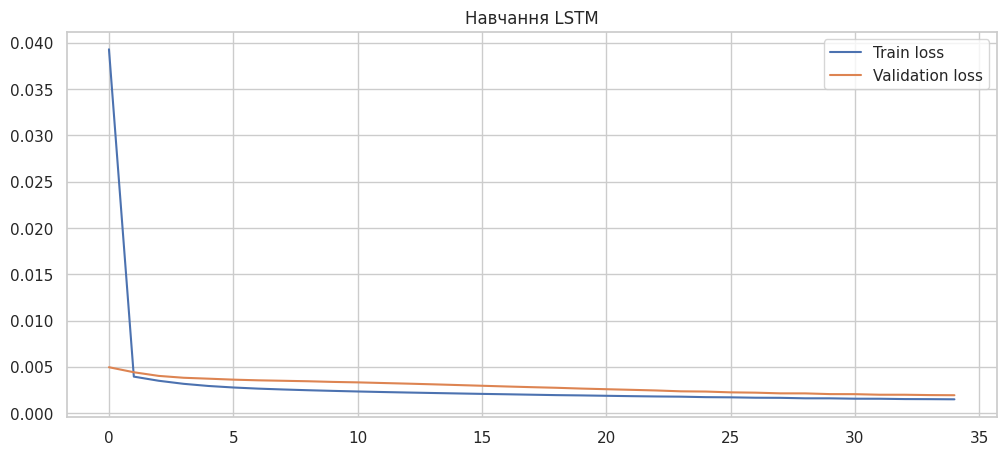

In [28]:
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = lstm_model.fit(X_train, y_train, epochs=35, batch_size=32, validation_split=0.15, shuffle=False, callbacks=[early_stop], verbose=1)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Навчання LSTM")
plt.legend()
plt.show()


In [29]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48)             │         9,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │         1,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,405 (126.59 KB)

 Trainable params: 10,801 (42.19 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 21,604 (84.39 KB)

In [30]:
lstm_scaled_pred = lstm_model.predict(X_test, verbose=0)
lstm_values = scaler.inverse_transform(lstm_scaled_pred).ravel()
print("Кількість прогнозів:", len(lstm_values))


Кількість прогнозів: 850


In [31]:
lstm_dates = series.index[target_indices[test_mask]]
lstm_pred = pd.Series(lstm_values, index=lstm_dates, name="LSTM")
assert lstm_pred.index.equals(test.index)
display(lstm_pred.head())


,LSTM
DATE,
2022-08-04,30.165842
2022-08-05,28.833391
2022-08-06,27.518747
2022-08-07,29.949490
2022-08-08,27.141283


In [32]:
lstm_scores = metrics(test, lstm_pred)
print("LSTM:", {k: round(v, 3) for k, v in lstm_scores.items()})
print("Увага: LSTM використовує фактичні попередні 30 днів тестового періоду (one-step-ahead).")


LSTM: {'MAE': 0.994, 'RMSE': np.float64(1.285), 'MAPE (%)': 4.227}
Увага: LSTM використовує фактичні попередні 30 днів тестового періоду (one-step-ahead).


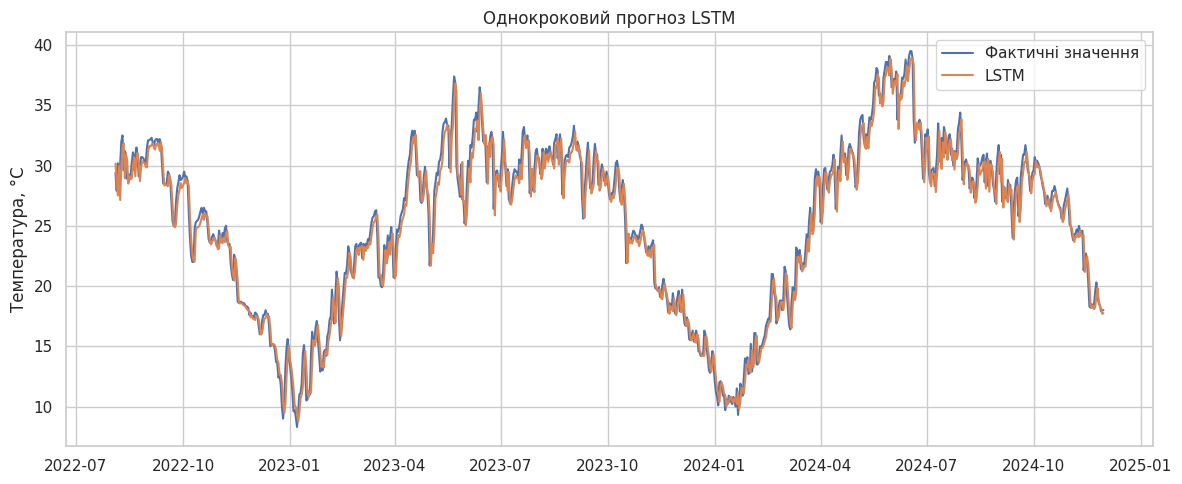

In [33]:
plt.plot(test.index, test, label="Фактичні значення")
plt.plot(lstm_pred.index, lstm_pred, label="LSTM")
plt.title("Однокроковий прогноз LSTM")
plt.ylabel("Температура, °C")
plt.legend()
plt.tight_layout()
plt.show()


Порівняння моделей

,MAE,RMSE,MAPE (%)
Модель,,,
LSTM,0.994,1.285,4.227
ARIMA,1.742,2.267,7.601
Prophet,2.069,2.648,9.349


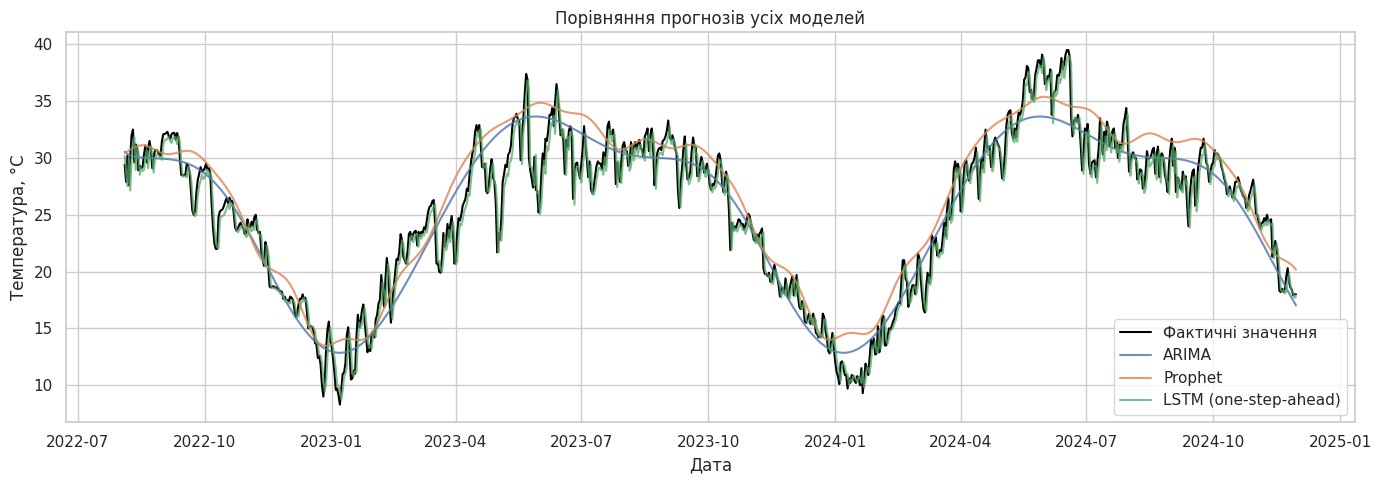

Найменша RMSE у моделі LSTM: 1.285 °C
Зауваження: ARIMA і Prophet прогнозують тестовий період без фактичних тестових значень, тоді як LSTM оцінена в однокроковому режимі з відомими попередніми спостереженнями. Тому пряме порівняння не повністю еквівалентне.


In [34]:
comparison = pd.DataFrame({"ARIMA": arima_scores, "Prophet": prophet_scores, "LSTM": lstm_scores}).T
comparison.index.name = "Модель"
display(comparison.round(3).sort_values("RMSE"))

plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Фактичні значення", linewidth=1.5, color="black")
plt.plot(arima_pred.index, arima_pred, label="ARIMA", alpha=0.8)
plt.plot(prophet_pred.index, prophet_pred, label="Prophet", alpha=0.8)
plt.plot(lstm_pred.index, lstm_pred, label="LSTM (one-step-ahead)", alpha=0.75)
plt.title("Порівняння прогнозів усіх моделей")
plt.ylabel("Температура, °C")
plt.xlabel("Дата")
plt.legend()
plt.tight_layout()
plt.show()

best_model = comparison["RMSE"].idxmin()
print(f"Найменша RMSE у моделі {best_model}: {comparison.loc[best_model, 'RMSE']:.3f} °C")
print("Зауваження: ARIMA і Prophet прогнозують тестовий період без фактичних тестових значень, тоді як LSTM оцінена в однокроковому режимі з відомими попередніми спостереженнями. Тому пряме порівняння не повністю еквівалентне.")
